# 01 - Data: WikiSQL

**Goal of this notebook.** Get the data, understand what it contains, and build the first tools of the
project: a loader, an object that represents a query, and an engine that runs a query on a table.

A code cell that starts with `%%writefile {CODE}/path/to/file.py` saves its content as a
code file of the project (in the folder `CODE`, see the setup cell). So the code in this notebook is exactly the code the project
uses

Files written by this notebook:

| File | Role |
|---|---|
| `src/t2s/data/download.py` | download and check the data |
| `src/t2s/query.py` | the object that represents a query |
| `src/t2s/data/wikisql.py` | load a split of the dataset |
| `src/t2s/data/stats.py` | statistics of the data |
| `src/t2s/eval/executor.py` | run a query on the SQLite table |
| `scripts/check_executor.py` | an independent check of the executor |

## Setup



In [1]:
import json, os, sys
from pathlib import Path

NOTEBOOK_NUMBER = 1

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/text2sql")
    CODE = "/content/code"                                      # where the notebooks write their code
    DATA_ROOT = "/content/data"                                 # the dataset (downloaded in each session)
    CKPT_DIR = "/content/drive/MyDrive/text2sql_checkpoints"    # the saved models
else:
    PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    CODE, DATA_ROOT, CKPT_DIR = str(PROJECT / "code"), str(PROJECT / "data"), str(PROJECT / "checkpoints")
os.chdir(PROJECT)   # the results are saved in the folder "results" of the project
os.makedirs(CKPT_DIR, exist_ok=True)


def rebuild_code(before):
    """Write again the code files of the notebooks 01 ... before-1 (their writefile cells)."""
    for path in sorted((PROJECT / "notebooks").glob("[0-9][0-9]_*.ipynb")):
        if int(path.name[:2]) >= before:
            continue
        for cell in json.loads(path.read_text())["cells"]:
            source = "".join(cell["source"])
            if cell["cell_type"] != "code" or not source.startswith("%%writefile"):
                continue
            first_line, _, body = source.partition("\n")
            words = first_line.split()
            target = Path(words[-1].replace("{CODE}", CODE))
            target.parent.mkdir(parents=True, exist_ok=True)
            with open(target, "a" if words[1] == "-a" else "w") as f:
                f.write(body if body.endswith("\n") else body + "\n")


for folder in ["src/t2s/data", "src/t2s/models", "src/t2s/decoding", "src/t2s/eval", "scripts", "configs"]:
    os.makedirs(f"{CODE}/{folder}", exist_ok=True)
rebuild_code(NOTEBOOK_NUMBER)
for package in ["src/t2s", "src/t2s/data", "src/t2s/models", "src/t2s/decoding", "src/t2s/eval"]:
    Path(f"{CODE}/{package}/__init__.py").touch()
sys.path.insert(0, f"{CODE}/src")

Mounted at /content/drive


## 1. Downloading the data

The data is one archive of about 26 MB in the official WikiSQL repository (BSD-3 license). The code below
downloads it, checks it, and unpacks it into the folder `data/` (which is not committed to git).

**The constants.** `WIKISQL_URL` is where the archive is. `WIKISQL_SHA256` is its *fingerprint*: a short code
computed from the content of the file. If the downloaded file gives another fingerprint, it is not the file I
expect, and the code stops. `EXPECTED_FILES` lists the nine files I need: for each split (train, dev, test),
the questions (`.jsonl`), the tables (`.tables.jsonl`) and the same tables as a SQLite database (`.db`).

In [2]:
%%writefile {CODE}/src/t2s/data/download.py
"""Download the WikiSQL data from the official repository."""

import hashlib
import tarfile
import urllib.request
from pathlib import Path

WIKISQL_URL = "https://raw.githubusercontent.com/salesforce/WikiSQL/master/data.tar.bz2"
WIKISQL_SHA256 = "755c728ab188e364575705c8641f3fafd86fb089cb8b08e8c03f01832aae0881"

EXPECTED_FILES = {
    f"{split}{suffix}"
    for split in ("train", "dev", "test")
    for suffix in (".jsonl", ".tables.jsonl", ".db")
}




Writing /content/code/src/t2s/data/download.py


**`_sha256`** computes the fingerprint. It reads the file in pieces of 1 MB, so a big file never has to be
loaded in memory at once.

In [3]:
%%writefile -a {CODE}/src/t2s/data/download.py
def _sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()




Appending to /content/code/src/t2s/data/download.py


**`extract_wikisql`** unpacks the archive. It keeps only the nine expected files and uses only the *name* of
each file (not its folder), so a damaged or malicious archive cannot write files in other places.

In [4]:
%%writefile -a {CODE}/src/t2s/data/download.py
def extract_wikisql(archive: Path, out_dir: Path) -> None:
    """Extract only the nine expected data files, flat into out_dir.

    Archive paths are ignored (only the file name is used), so a crafted archive
    cannot write outside out_dir.
    """
    out_dir.mkdir(parents=True, exist_ok=True)
    with tarfile.open(archive, "r:bz2") as tar:
        for member in tar:
            name = Path(member.name).name
            if not member.isfile() or name not in EXPECTED_FILES:
                continue
            with tar.extractfile(member) as src, open(out_dir / name, "wb") as dst:
                while chunk := src.read(1 << 20):
                    dst.write(chunk)




Appending to /content/code/src/t2s/data/download.py


**`download_wikisql`** is the function I call. If the nine files are already there it does nothing; otherwise
it downloads the archive, checks the fingerprint, unpacks it, and deletes the archive.

In [5]:
%%writefile -a {CODE}/src/t2s/data/download.py
def download_wikisql(dest: str | Path = "data", force: bool = False) -> Path:
    """Download and extract WikiSQL into `dest/wikisql`. Returns that folder.

    Does nothing if all nine files are already there, unless force=True.
    """
    out_dir = Path(dest) / "wikisql"
    if not force and all((out_dir / name).exists() for name in EXPECTED_FILES):
        return out_dir

    out_dir.mkdir(parents=True, exist_ok=True)
    archive = out_dir / "data.tar.bz2"
    urllib.request.urlretrieve(WIKISQL_URL, archive)

    found = _sha256(archive)
    if found != WIKISQL_SHA256:
        raise RuntimeError(
            f"Checksum mismatch for the downloaded archive.\n"
            f"  expected {WIKISQL_SHA256}\n  found    {found}"
        )
    extract_wikisql(archive, out_dir)
    archive.unlink()
    return out_dir


Appending to /content/code/src/t2s/data/download.py


In [6]:
from t2s.data.download import download_wikisql

data_dir = download_wikisql(DATA_ROOT)
for path in sorted(data_dir.iterdir()):
    print(f"{path.name:20s} {path.stat().st_size / 1e6:7.1f} MB")

dev.db                  12.3 MB
dev.jsonl                1.6 MB
dev.tables.jsonl         4.7 MB
test.db                 24.5 MB
test.jsonl               3.0 MB
test.tables.jsonl        9.9 MB
train.db                85.3 MB
train.jsonl             10.5 MB
train.tables.jsonl      33.2 MB


**What I observe.** Nine files: three splits with questions, tables and a database each. The largest is
`train.db` (about 85 MB).

## 2. What the raw files contain

I look at the first record of the training file and at its table, before writing any tool.

In [7]:
import json

with open(data_dir / "train.jsonl") as f:
    record = json.loads(f.readline())
print(json.dumps(record, indent=2))

with open(data_dir / "train.tables.jsonl") as f:
    table = json.loads(f.readline())
print()
print("table id :", table["id"])
print("header   :", table["header"])
print("types    :", table["types"])
print("first row:", table["rows"][0])

{
  "phase": 1,
  "table_id": "1-1000181-1",
  "question": "Tell me what the notes are for South Australia ",
  "sql": {
    "sel": 5,
    "conds": [
      [
        3,
        0,
        "SOUTH AUSTRALIA"
      ]
    ],
    "agg": 0
  }
}

table id : 1-1000181-1
header   : ['State/territory', 'Text/background colour', 'Format', 'Current slogan', 'Current series', 'Notes']
types    : ['text', 'text', 'text', 'text', 'text', 'text']
first row: ['Australian Capital Territory', 'blue/white', 'Yaa·nna', 'ACT · CELEBRATION OF A CENTURY 2013', 'YIL·00A', 'Slogan screenprinted on plate']


**What I observe.** The query is **not** stored as SQL text. It is stored as indexes:

- `sel` is the index of the selected column in the table header (here `5`, which is `Notes`);
- `agg` is the index of the aggregator: 0 none, 1 MAX, 2 MIN, 3 COUNT, 4 SUM, 5 AVG;
- each condition is `[column index, operator index, value]`, with operators 0 `=`, 1 `>`, 2 `<`.
  Here `[3, 0, "SOUTH AUSTRALIA"]` means: column 3 (`Current slogan`) equals `SOUTH AUSTRALIA`.

So this record is the query `SELECT Notes FROM table WHERE Current slogan = 'SOUTH AUSTRALIA'`. The next section
builds an object that holds this information.

## 3. The query object

A small class that holds a query and can translate it. It is used by almost every other part of the project.

**The symbols.** `AGG_OPS` and `COND_OPS` translate the indexes of the data into symbols. (The fourth
operator, `OP`, never occurs in the data.)

In [8]:
%%writefile {CODE}/src/t2s/query.py
"""The structured form of a WikiSQL query.

WikiSQL does not store SQL text. A query is a column to select, an aggregator,
and a list of conditions, all given as indexes into the table's column list.
"""

from dataclasses import dataclass

AGG_OPS = ("", "MAX", "MIN", "COUNT", "SUM", "AVG")
COND_OPS = ("=", ">", "<", "OP")




Writing /content/code/src/t2s/query.py


**`Condition`** is one WHERE condition: a column index, an operator index, and a value (text or number).
`@dataclass` creates a class that simply holds named fields; `frozen=True` makes it unchangeable.

In [9]:
%%writefile -a {CODE}/src/t2s/query.py
@dataclass(frozen=True)
class Condition:
    column: int
    op: int
    value: str | int | float




Appending to /content/code/src/t2s/query.py


**`Query`** holds the selected column, the aggregator, and the conditions. The conditions are kept in a tuple
(unchangeable), so two queries can be compared.

In [10]:
%%writefile -a {CODE}/src/t2s/query.py
@dataclass(frozen=True)
class Query:
    select: int
    agg: int
    conds: tuple[Condition, ...] = ()



Appending to /content/code/src/t2s/query.py


**`from_dict`** builds a `Query` from the `sql` field of a record of the data.

In [11]:
%%writefile -a {CODE}/src/t2s/query.py
    @classmethod
    def from_dict(cls, d: dict) -> "Query":
        """Build a query from the `sql` field of a WikiSQL record."""
        conds = tuple(Condition(c, o, v) for c, o, v in d["conds"])
        return cls(select=d["sel"], agg=d["agg"], conds=conds)



Appending to /content/code/src/t2s/query.py


**`canonical`** gives a form that is the same for queries with the same meaning: the conditions are sorted (their
order does not matter), and the values are compared as lowercase text with single spaces. Later I use it to decide
if a predicted query equals the gold query (the *exact match* metric).

In [12]:
%%writefile -a {CODE}/src/t2s/query.py
    def canonical(self) -> tuple:
        """A form that is equal for queries with the same meaning.

        The order of the conditions is ignored, and values are compared as lowercase
        text with single spaces (so "Tunisia" and " tunisia" are the same value).
        """
        conds = sorted((c.column, c.op, " ".join(str(c.value).lower().split())) for c in self.conds)
        return (self.select, self.agg, tuple(conds))



Appending to /content/code/src/t2s/query.py


**`to_sql`** writes the query as readable SQL with the real column names. I use it only to display queries.

In [13]:
%%writefile -a {CODE}/src/t2s/query.py
    def to_sql(self, header: list[str] | tuple[str, ...]) -> str:
        """Readable SQL text, using the real column names of the table."""
        column = header[self.select]
        select = f"{AGG_OPS[self.agg]}({column})" if self.agg else column
        sql = f"SELECT {select} FROM table"
        if self.conds:
            parts = []
            for c in self.conds:
                value = f"'{c.value}'" if isinstance(c.value, str) else str(c.value)
                parts.append(f"{header[c.column]} {COND_OPS[c.op]} {value}")
            sql += " WHERE " + " AND ".join(parts)
        return sql


Appending to /content/code/src/t2s/query.py


In [14]:
from t2s.query import Query

query = Query.from_dict(record["sql"])
print(query)
print(query.to_sql(table["header"]))

# Two conditions written in a different order have the same meaning:
a = Query.from_dict({"sel": 0, "agg": 3, "conds": [[1, 0, "Tunisia"], [2, 1, 5]]})
b = Query.from_dict({"sel": 0, "agg": 3, "conds": [[2, 1, 5], [1, 0, " tunisia"]]})
print("same canonical form:", a.canonical() == b.canonical())

Query(select=5, agg=0, conds=(Condition(column=3, op=0, value='SOUTH AUSTRALIA'),))
SELECT Notes FROM table WHERE Current slogan = 'SOUTH AUSTRALIA'
same canonical form: True


**What I observe.** The record of the previous section becomes the readable query I predicted. Two queries whose
conditions are in a different order (and whose values differ only by case or spaces) have the same canonical form.

## 4. Loading a split

The loader reads the questions and the tables of a split and joins them: every example gets the column names of
its table and its `Query` object.

**The imports and the names of the splits.**

In [15]:
%%writefile {CODE}/src/t2s/data/wikisql.py
"""Loading the WikiSQL files.

Each split has three files:
    <split>.jsonl         one record per line: question, table_id and the query
    <split>.tables.jsonl  one table per line: id, column names, column types, rows
    <split>.db            the same tables as SQLite, used to execute queries
"""

import json
from dataclasses import dataclass
from pathlib import Path

from t2s.query import Query

SPLITS = ("train", "dev", "test")




Writing /content/code/src/t2s/data/wikisql.py


**`Example`** is one question with everything needed to work with it: the question, the id of its table, the
column names (`header`), their types (text or numeric), and the query.

In [16]:
%%writefile -a {CODE}/src/t2s/data/wikisql.py
@dataclass(frozen=True)
class Example:
    question: str
    table_id: str
    header: tuple[str, ...]
    types: tuple[str, ...]
    query: Query




Appending to /content/code/src/t2s/data/wikisql.py


**`_read_jsonl`** reads a file with one JSON object per line.

In [17]:
%%writefile -a {CODE}/src/t2s/data/wikisql.py
def _read_jsonl(path: Path) -> list[dict]:
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f]




Appending to /content/code/src/t2s/data/wikisql.py


**`load_split`** reads one split. It first loads the tables into a dictionary (id to table), then reads the
questions and attaches to each the header and types of its table.

In [18]:
%%writefile -a {CODE}/src/t2s/data/wikisql.py
def load_split(data_dir: str | Path, split: str) -> list[Example]:
    """Read one split and attach the column names of each record's table."""
    if split not in SPLITS:
        raise ValueError(f"split must be one of {SPLITS}, got {split!r}")
    data_dir = Path(data_dir)

    tables = {t["id"]: t for t in _read_jsonl(data_dir / f"{split}.tables.jsonl")}
    examples = []
    for record in _read_jsonl(data_dir / f"{split}.jsonl"):
        table = tables[record["table_id"]]
        examples.append(
            Example(
                question=record["question"],
                table_id=record["table_id"],
                header=tuple(table["header"]),
                types=tuple(table["types"]),
                query=Query.from_dict(record["sql"]),
            )
        )
    return examples




Appending to /content/code/src/t2s/data/wikisql.py


**`db_path`** gives the path of the SQLite file of a split.

In [19]:
%%writefile -a {CODE}/src/t2s/data/wikisql.py
def db_path(data_dir: str | Path, split: str) -> Path:
    return Path(data_dir) / f"{split}.db"


Appending to /content/code/src/t2s/data/wikisql.py


In [20]:
from t2s.data.wikisql import load_split

splits = {name: load_split(data_dir, name) for name in ["train", "dev", "test"]}
for name, examples in splits.items():
    print(f"{name:6s} {len(examples):6d} examples")

print()
for ex in splits["train"][:5]:
    print("Question:", ex.question.strip())
    print("Columns :", " | ".join(ex.header))
    print("SQL     :", ex.query.to_sql(ex.header))
    print()

train   56355 examples
dev      8421 examples
test    15878 examples

Question: Tell me what the notes are for South Australia
Columns : State/territory | Text/background colour | Format | Current slogan | Current series | Notes
SQL     : SELECT Notes FROM table WHERE Current slogan = 'SOUTH AUSTRALIA'

Question: What is the current series where the new series began in June 2011?
Columns : State/territory | Text/background colour | Format | Current slogan | Current series | Notes
SQL     : SELECT Current series FROM table WHERE Notes = 'New series began in June 2011'

Question: What is the format for South Australia?
Columns : State/territory | Text/background colour | Format | Current slogan | Current series | Notes
SQL     : SELECT Format FROM table WHERE State/territory = 'South Australia'

Question: Name the background colour for the Australian Capital Territory
Columns : State/territory | Text/background colour | Format | Current slogan | Current series | Notes
SQL     : SELECT Te

**What I observe.** 56,355 training, 8,421 dev and 15,878 test questions, 80,654 in total. The indexes are read
correctly: the readable SQL matches each question.

## 5. Statistics of the data

The functions below measure the properties of the data that matter for the design of the models.

**The imports.**

In [21]:
%%writefile {CODE}/src/t2s/data/stats.py
"""Descriptive statistics of a WikiSQL split."""

import json
import re
import statistics
from collections import Counter
from pathlib import Path

from t2s.data.wikisql import Example




Writing /content/code/src/t2s/data/stats.py


**`_squash`** replaces every run of spaces and line breaks in a text by a single space, so that the comparison of a value with the question is not disturbed by extra spaces.

In [22]:
%%writefile -a {CODE}/src/t2s/data/stats.py
def _squash(text: str) -> str:
    return re.sub(r"\s+", " ", str(text)).strip()




Appending to /content/code/src/t2s/data/stats.py


**`table_overlap`** counts the tables shared by each pair of splits. WikiSQL splits by table, so all counts should
be 0.

In [23]:
%%writefile -a {CODE}/src/t2s/data/stats.py
def table_overlap(splits: dict[str, list[Example]]) -> dict[tuple[str, str], int]:
    """Number of tables shared by each pair of splits (should all be 0)."""
    ids = {name: {ex.table_id for ex in examples} for name, examples in splits.items()}
    names = list(ids)
    return {
        (a, b): len(ids[a] & ids[b])
        for i, a in enumerate(names)
        for b in names[i + 1 :]
    }




Appending to /content/code/src/t2s/data/stats.py


**`value_in_question`** measures how often the value of a condition appears in the question text: exactly as
written (`exact`), only when upper/lower case is ignored (`case_only`), or not at all (`not_found`).

In [24]:
%%writefile -a {CODE}/src/t2s/data/stats.py
def value_in_question(examples: list[Example]) -> dict[str, float]:
    """How often a condition value appears inside the question text.

    'exact' means as written; 'case_only' means only after ignoring upper/lower case.
    """
    exact = case_only = total = 0
    for ex in examples:
        question = _squash(ex.question)
        for cond in ex.query.conds:
            total += 1
            value = _squash(cond.value)
            if value in question:
                exact += 1
            elif value.lower() in question.lower():
                case_only += 1
    return {
        "n_values": total,
        "exact": exact / total,
        "case_only": case_only / total,
        "not_found": (total - exact - case_only) / total,
    }




Appending to /content/code/src/t2s/data/stats.py


**`queries_touching_text_in_numeric_columns`** measures a data-quality problem: some columns are typed as numeric
but contain text cells (for example `55,000`). It counts the queries that use such a column.

In [25]:
%%writefile -a {CODE}/src/t2s/data/stats.py
def queries_touching_text_in_numeric_columns(
    tables_path: str | Path, examples: list[Example]
) -> dict[str, float]:
    """Share of queries that use a numeric ("real") column holding some non-numeric cells.

    Example: a column typed as real that contains the text '55,000'. Such cells make
    comparisons with numbers behave unexpectedly, so this is a data-quality fact.
    """
    dirty: dict[str, set[int]] = {}
    with open(tables_path, encoding="utf-8") as f:
        for line in f:
            table = json.loads(line)
            columns = {
                i
                for i, kind in enumerate(table["types"])
                if kind == "real"
                and not all(isinstance(row[i], (int, float)) for row in table["rows"])
            }
            if columns:
                dirty[table["id"]] = columns

    count = 0
    for ex in examples:
        used = {ex.query.select} | {c.column for c in ex.query.conds}
        if used & dirty.get(ex.table_id, set()):
            count += 1
    return {"n_queries": count, "share": count / len(examples)}




Appending to /content/code/src/t2s/data/stats.py


**`summarize`** collects the counts and distributions of one split in a dictionary: number of examples and tables,
aggregators, number of conditions, operators, question lengths, columns per table, and `value_in_question`.

In [26]:
%%writefile -a {CODE}/src/t2s/data/stats.py
def summarize(examples: list[Example]) -> dict:
    """Counts and distributions that describe one split."""
    question_words = sorted(len(ex.question.split()) for ex in examples)
    n_columns = [len(ex.header) for ex in examples]
    return {
        "n_examples": len(examples),
        "n_tables": len({ex.table_id for ex in examples}),
        "agg": dict(sorted(Counter(ex.query.agg for ex in examples).items())),
        "n_conds": dict(sorted(Counter(len(ex.query.conds) for ex in examples).items())),
        "cond_op": dict(
            sorted(Counter(c.op for ex in examples for c in ex.query.conds).items())
        ),
        "question_words": {
            "mean": statistics.mean(question_words),
            "median": statistics.median(question_words),
            "p95": question_words[int(0.95 * len(question_words))],
            "max": question_words[-1],
        },
        "columns_per_table": {
            "mean": statistics.mean(n_columns),
            "max": max(n_columns),
        },
        "value_in_question": value_in_question(examples),
    }


Appending to /content/code/src/t2s/data/stats.py


### 5.1 The split is made by table

If the same table were in train and test, a model could memorize its column names and common values. WikiSQL avoids
this, so the test set measures generalization to tables the model has never seen.

In [27]:
from t2s.data.stats import table_overlap

for (a, b), n in table_overlap(splits).items():
    print(f"tables shared by {a} and {b}: {n}")

tables shared by train and dev: 0
tables shared by train and test: 0
tables shared by dev and test: 0


**What I observe.** No table is shared between any two splits. The test results will therefore measure
generalization to new tables and new column names.

### 5.2 Sizes and distributions

In [28]:
from pathlib import Path
import pandas as pd
from t2s.data.stats import summarize

stats = {name: summarize(examples) for name, examples in splits.items()}

out_dir = Path("results/phase1_data")
out_dir.mkdir(parents=True, exist_ok=True)
(out_dir / "stats.json").write_text(json.dumps(stats, indent=2))

pd.DataFrame({
    name: {
        "examples": s["n_examples"],
        "tables": s["n_tables"],
        "question words, mean": round(s["question_words"]["mean"], 1),
        "question words, 95th percentile": s["question_words"]["p95"],
        "question words, max": s["question_words"]["max"],
        "columns per table, mean": round(s["columns_per_table"]["mean"], 1),
        "columns per table, max": s["columns_per_table"]["max"],
    }
    for name, s in stats.items()
})

,train,dev,test
examples,56355.0,8421.0,15878.0
tables,17984.0,2630.0,5069.0
"question words, mean",11.6,11.7,11.7
"question words, 95th percentile",20.0,20.0,20.0
"question words, max",44.0,58.0,43.0
"columns per table, mean",6.4,6.3,6.4
"columns per table, max",44.0,20.0,23.0


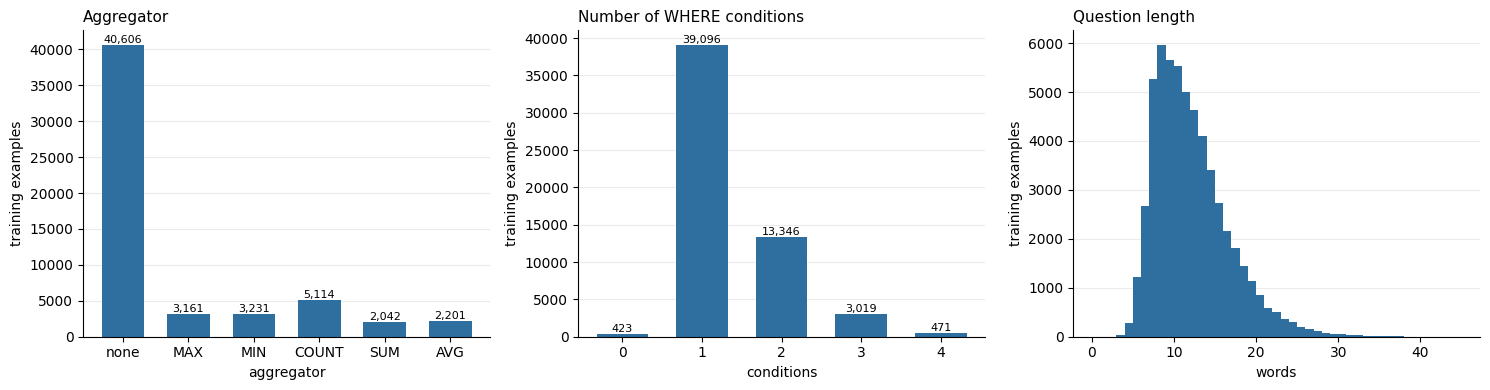

In [29]:
import matplotlib.pyplot as plt
from t2s.query import AGG_OPS

COLOR = "#2f6f9f"
train = stats["train"]

def bars(ax, labels, values, title, xlabel):
    xs = range(len(values))
    ax.bar(xs, values, color=COLOR, width=0.65)
    ax.set_xticks(list(xs))
    ax.set_xticklabels(labels)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("training examples")
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    for x, v in zip(xs, values):
        ax.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=8)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
agg = train["agg"]
bars(axes[0], [AGG_OPS[k] or "none" for k in agg], list(agg.values()), "Aggregator", "aggregator")
n_conds = train["n_conds"]
bars(axes[1], list(n_conds), list(n_conds.values()), "Number of WHERE conditions", "conditions")

lengths = [len(ex.question.split()) for ex in splits["train"]]
axes[2].hist(lengths, bins=range(0, max(lengths) + 2), color=COLOR)
axes[2].set_title("Question length", loc="left", fontsize=11)
axes[2].set_xlabel("words")
axes[2].set_ylabel("training examples")
axes[2].grid(axis="y", alpha=0.25)
axes[2].set_axisbelow(True)
for spine in ("top", "right"):
    axes[2].spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig(out_dir / "distributions.png", dpi=150)
plt.show()

**What I observe.**

- The three splits have similar properties: questions have about 11.6 words on average (95% have 20 words or fewer),
  and tables have about 6.4 columns.
- 72% of the questions have **no aggregator**; COUNT is the most frequent aggregator (9%).
- 69% of the queries have **one** condition, 24% have two, and 423 queries (0.8%) have none.
- So the *shape* of a query is simple and easy to predict. The difficult part is choosing the **right column and
  the right value**.

### 5.3 Are the values of the conditions written in the question?

This decides how a model can produce values. If a value is always a piece of the question, the model only has to
copy it.

In [30]:
for name, s in stats.items():
    v = s["value_in_question"]
    print(f"{name:6s} {v['n_values']:6d} values | exactly in question: {v['exact']:.1%} | "
          f"only when ignoring case: {v['case_only']:.1%} | not found: {v['not_found']:.1%}")

print()
shown = 0
for ex in splits["train"]:
    for cond in ex.query.conds:
        value = str(cond.value)
        if value not in ex.question and value.lower() in ex.question.lower():
            print("question:", ex.question.strip())
            print("value   :", value)
            print()
            shown += 1
    if shown >= 4:
        break

train   76729 values | exactly in question: 71.2% | only when ignoring case: 28.8% | not found: 0.0%
dev     11545 values | exactly in question: 72.3% | only when ignoring case: 27.7% | not found: 0.0%
test    21846 values | exactly in question: 71.5% | only when ignoring case: 28.5% | not found: 0.0%

question: Tell me what the notes are for South Australia
value   : SOUTH AUSTRALIA

question: What is the current series where the new series began in June 2011?
value   : New series began in June 2011

question: how many times is the fuel propulsion is cng?
value   : CNG

question: how many times is the model ge40lfr?
value   : GE40LFR



**What I observe.** In the training set, 71.2% of the values appear in the question exactly as written, and the
other 28.8% appear once upper/lower case is ignored. **None is missing**: every value is a piece of the question.
This has two consequences:

1. Lowercasing everything loses nothing that matters (the database text is lowercase as well).
2. A model that could *copy* words from the question would not need to know every possible value. This is the reason
   for the copy mechanism I add later.

## 6. Running a query on the database

To know if a predicted query is correct, I can run it on the table and compare its answer with the answer of the gold
query (*execution accuracy*). This needs an engine that runs a `Query` on the SQLite file.

**The behavior.** It follows the official WikiSQL engine: text values are lowercased (the database text is
lowercase), and the value of a condition on a numeric column is turned into a number. `_NUMBER` is a pattern that
finds a number inside a text.

In [31]:
%%writefile {CODE}/src/t2s/eval/executor.py
"""Run a WikiSQL query on the SQLite database and return its answer.

Execution accuracy compares the answer of the predicted query with the answer of
the gold query, so a query written differently can still count as correct.

Behavior follows the official WikiSQL engine:
    - text values are lowercased (the database text is already lowercase),
    - values for numeric ("real") columns are converted to numbers.
"""

import re
import sqlite3
from pathlib import Path

from t2s.query import AGG_OPS, COND_OPS, Query

_NUMBER = re.compile(r"[-+]?\d*\.\d+|\d+")




Writing /content/code/src/t2s/eval/executor.py


**`to_number`** turns a text such as `1,200` or `about 15 m` into a number. It first tries to read the whole text
(removing commas); otherwise it takes the first number found in the text, and raises an error if there is none.

In [32]:
%%writefile -a {CODE}/src/t2s/eval/executor.py
def to_number(value: str) -> float:
    """Turn text such as '1,200' or 'about 15 m' into a float."""
    try:
        return float(value.replace(",", ""))
    except ValueError:
        found = _NUMBER.findall(value)
        if not found:
            raise ValueError(f"no number in {value!r}")
        return float(found[0])




Appending to /content/code/src/t2s/eval/executor.py


**`SqliteExecutor`** opens the database file in read-only mode, so it can never change the data.

In [33]:
%%writefile -a {CODE}/src/t2s/eval/executor.py
class SqliteExecutor:
    def __init__(self, db_file: str | Path):
        self.conn = sqlite3.connect(f"file:{db_file}?mode=ro", uri=True)
        self._column_types: dict[str, dict[str, str]] = {}

    def close(self) -> None:
        self.conn.close()



Appending to /content/code/src/t2s/eval/executor.py


**`_table_name`**: in the database, the table with the id `1-1000181-1` is called `table_1_1000181_1`.

In [34]:
%%writefile -a {CODE}/src/t2s/eval/executor.py
    @staticmethod
    def _table_name(table_id: str) -> str:
        return "table_" + table_id.replace("-", "_")



Appending to /content/code/src/t2s/eval/executor.py


**`_types`** reads the type of each column of a table (text or numeric) and remembers it. SQLite returns the type in
capitals (`REAL`), so it is converted to lowercase. (My first version compared it with `real`, so numeric values
were never converted. A unit test showed it.)

In [35]:
%%writefile -a {CODE}/src/t2s/eval/executor.py
    def _types(self, table: str) -> dict[str, str]:
        if table not in self._column_types:
            rows = self.conn.execute(f"PRAGMA table_info({table})").fetchall()
            if not rows:
                raise ValueError(f"unknown table {table!r}")
            # PRAGMA returns the declared type in capitals ("REAL"), so lowercase it.
            self._column_types[table] = {name: ctype.lower() for _, name, ctype, *_ in rows}
        return self._column_types[table]



Appending to /content/code/src/t2s/eval/executor.py


**`execute`** builds the SQL and runs it: the selected column (with the aggregator), then one condition for each
`Condition`. The values are not written into the SQL text but passed separately (`?`), so the database handles the
quotes by itself. Invalid queries (a column that does not exist, a text without a number on a numeric column) raise an
error.

In [36]:
%%writefile -a {CODE}/src/t2s/eval/executor.py
    def execute(self, table_id: str, query: Query) -> list:
        """Return the list of result values. Raises on an invalid query."""
        table = self._table_name(table_id)
        types = self._types(table)

        select = f"col{query.select}"
        if select not in types:
            raise ValueError(f"column index {query.select} out of range")
        if query.agg:
            select = f"{AGG_OPS[query.agg]}({select})"

        clauses, params = [], []
        for cond in query.conds:
            column = f"col{cond.column}"
            if column not in types:
                raise ValueError(f"column index {cond.column} out of range")
            value = cond.value
            if isinstance(value, str):
                value = value.lower()
            if types[column] == "real" and not isinstance(value, (int, float)):
                value = to_number(value)
            clauses.append(f"{column} {COND_OPS[cond.op]} ?")
            params.append(value)

        sql = f"SELECT {select} FROM {table}"
        if clauses:
            sql += " WHERE " + " AND ".join(clauses)
        return [row[0] for row in self.conn.execute(sql, params).fetchall()]


Appending to /content/code/src/t2s/eval/executor.py


In [37]:
from t2s.data.wikisql import db_path
from t2s.eval.executor import SqliteExecutor

executor = SqliteExecutor(db_path(data_dir, "dev"))
results, errors = [], 0
for ex in splits["dev"]:
    try:
        results.append(executor.execute(ex.table_id, ex.query))
    except Exception:
        results.append(None)
        errors += 1

empty = sum(1 for r in results if r is not None and (len(r) == 0 or r == [None]))
print(f"dev gold queries: {len(results)} | errors: {errors} | empty answers: {empty} ({empty / len(results):.1%})")
print()
for ex, result in zip(splits["dev"][:4], results):
    print("Question:", ex.question.strip())
    print("SQL     :", ex.query.to_sql(ex.header))
    print("Answer  :", result[:5])
    print()

dev gold queries: 8421 | errors: 0 | empty answers: 657 (7.8%)

Question: What position does the player who played for butler cc (ks) play?
SQL     : SELECT Position FROM table WHERE School/Club Team = 'Butler CC (KS)'
Answer  : ['guard-forward']

Question: How many schools did player number 3 play at?
SQL     : SELECT COUNT(School/Club Team) FROM table WHERE No. = '3'
Answer  : [1]

Question: What school did player number 21 play for?
SQL     : SELECT School/Club Team FROM table WHERE No. = '21'
Answer  : ['duke']

Question: Who is the player that wears number 42?
SQL     : SELECT Player FROM table WHERE No. = '42'
Answer  : ['art long']



**What I observe.** All 8,421 gold dev queries run without error, and the answers look right. But **7.8% of the gold
queries return an empty answer**: the annotation of these questions is not consistent with the table. This matters for
the metrics: a wrong query that also returns an empty answer would be counted as correct. I will therefore report
the *exact match* too, and the execution accuracy computed without the empty-answer questions.

### A second opinion

A test on small examples is not enough to trust the executor, so I wrote an **independent** check: it answers the same
queries in plain Python from the raw table rows, without SQLite, and the two answers must agree.

**The beginning of the script.** Its docstring explains the idea; `sys.path.insert` lets the script find the
project code when it is run from the command line.

In [38]:
%%writefile {CODE}/scripts/check_executor.py
"""Check the SQLite executor against an independent evaluator.

The independent evaluator reads the raw table rows from `<split>.tables.jsonl` and
filters them in plain Python, without SQLite. For every gold query of a split, both
must give the same answer.

Some "real" columns contain text cells (for example '55,000'). SQLite orders text
after numbers, which a plain Python comparison does not reproduce, so queries that
touch such a column are counted separately and not treated as disagreements.

Usage:
    python scripts/check_executor.py data/wikisql [dev test]
"""

import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / "src"))

from t2s.data.wikisql import db_path, load_split  # noqa: E402
from t2s.eval.executor import SqliteExecutor, to_number  # noqa: E402



Writing /content/code/scripts/check_executor.py


**`COMPARE`** gives, for each operator index, the Python comparison (`=`, `>`, `<`).

In [39]:
%%writefile -a {CODE}/scripts/check_executor.py
COMPARE = {0: lambda a, b: a == b, 1: lambda a, b: a > b, 2: lambda a, b: a < b}




Appending to /content/code/scripts/check_executor.py


**`is_clean`** says if a query can be checked this way. If a numeric column contains text cells (for example `55,000`),
SQLite orders text after numbers, which plain Python does not reproduce, so these queries are counted separately.
The same is true for MAX, MIN, SUM and AVG of a text column.

In [40]:
%%writefile -a {CODE}/scripts/check_executor.py
def is_clean(table: dict, query) -> bool:
    """True if every numeric column used by the query holds only numbers."""
    if query.agg in (1, 2, 4, 5) and table["types"][query.select] != "real":
        return False  # MAX, MIN, SUM or AVG of a text column: no plain-Python equivalent
    used = {query.select} | {c.column for c in query.conds}
    return all(
        table["types"][i] != "real"
        or all(isinstance(row[i], (int, float)) for row in table["rows"])
        for i in used
    )




Appending to /content/code/scripts/check_executor.py


**`python_answer`** is the independent evaluator: it keeps the rows that satisfy all the conditions, takes the selected
column, and applies the aggregator.

In [41]:
%%writefile -a {CODE}/scripts/check_executor.py
def python_answer(table: dict, query) -> list:
    selected = []
    for row in table["rows"]:
        keep = True
        for cond in query.conds:
            cell = row[cond.column]
            if table["types"][cond.column] == "real":
                value = cond.value if isinstance(cond.value, (int, float)) else to_number(cond.value)
                keep = COMPARE[cond.op](float(cell), float(value))
            else:
                keep = COMPARE[cond.op](str(cell).lower(), str(cond.value).lower())
            if not keep:
                break
        if keep:
            selected.append(row[query.select])

    if query.agg == 0:
        return selected
    if query.agg == 3:
        return [len(selected)]
    numbers = [float(v) for v in selected]
    if not numbers:
        return [None]
    aggregates = {1: max, 2: min, 4: sum, 5: lambda x: sum(x) / len(x)}
    return [aggregates[query.agg](numbers)]




Appending to /content/code/scripts/check_executor.py


**`same_answer`** compares two answers (numbers with a small tolerance, text ignoring case).

In [42]:
%%writefile -a {CODE}/scripts/check_executor.py
def same_answer(a: list, b: list) -> bool:
    if len(a) != len(b):
        return False
    for x, y in zip(a, b):
        if isinstance(x, (int, float)) and isinstance(y, (int, float)):
            if abs(x - y) > 1e-6 * max(1.0, abs(x)):
                return False
        elif str(x).lower() != str(y).lower():
            return False
    return True




Appending to /content/code/scripts/check_executor.py


**`check_split`** runs both engines on every gold query of a split and counts errors, agreements and disagreements.

In [43]:
%%writefile -a {CODE}/scripts/check_executor.py
def check_split(data_dir: Path, split: str) -> None:
    with open(data_dir / f"{split}.tables.jsonl", encoding="utf-8") as f:
        tables = {t["id"]: t for t in map(json.loads, f)}
    executor = SqliteExecutor(db_path(data_dir, split))
    examples = load_split(data_dir, split)

    errors = clean = clean_disagree = skipped = 0
    for ex in examples:
        try:
            sqlite_answer = executor.execute(ex.table_id, ex.query)
        except Exception:
            errors += 1
            continue
        table = tables[ex.table_id]
        if not is_clean(table, ex.query):
            skipped += 1
            continue
        clean += 1
        if not same_answer(sqlite_answer, python_answer(table, ex.query)):
            clean_disagree += 1

    print(
        f"{split}: {len(examples)} gold queries | executor errors: {errors} | "
        f"clean queries compared: {clean}, disagreements: {clean_disagree} | "
        f"skipped (text in a numeric column): {skipped}"
    )




Appending to /content/code/scripts/check_executor.py


**The entry point** of the script.

In [44]:
%%writefile -a {CODE}/scripts/check_executor.py
if __name__ == "__main__":
    folder = Path(sys.argv[1])
    for name in sys.argv[2:] or ["dev", "test"]:
        check_split(folder, name)


Appending to /content/code/scripts/check_executor.py


In [45]:
!python {CODE}/scripts/check_executor.py {data_dir} dev test

dev: 8421 gold queries | executor errors: 0 | clean queries compared: 5732, disagreements: 0 | skipped (text in a numeric column): 2689
test: 15878 gold queries | executor errors: 0 | clean queries compared: 10959, disagreements: 0 | skipped (text in a numeric column): 4919


**What I observe.** On the queries that can be compared, the two engines agree on **every** query: 5,732 of 5,732 on dev
and 10,959 of 10,959 on test, with no error. So I trust the executor.

### Text inside numeric columns

The queries that could not be compared above use a numeric column that contains text cells. I measure how many there
are.

In [46]:
from t2s.data.stats import queries_touching_text_in_numeric_columns

dirty = {
    name: queries_touching_text_in_numeric_columns(data_dir / f"{name}.tables.jsonl", examples)
    for name, examples in splits.items()
}
for name, d in dirty.items():
    print(f"{name:6s} queries using a numeric column that contains text: {d['n_queries']:6d} ({d['share']:.1%})")

path = out_dir / "stats_extra.json"
path.write_text(json.dumps({"text_in_numeric_columns": dirty}, indent=2))
print("saved", path)

train  queries using a numeric column that contains text:  17303 (30.7%)
dev    queries using a numeric column that contains text:   2689 (31.9%)
test   queries using a numeric column that contains text:   4919 (31.0%)
saved results/phase1_data/stats_extra.json


**What I observe.** About 31% of the queries in each split use such a column. Comparisons with `>` and `<` on these
columns can behave in a surprising way. This is a property of the data and not of the model, and I keep it in mind for
the error analysis.

## 7. Summary of this notebook

**What I built:** a checked download, a loader, a `Query` object, statistics, and an execution engine validated by an
independent check.

**What I learned about the data:**

1. The split is made by table: no table is shared, so the test set contains new schemas.
2. The queries have a simple shape (mostly no aggregator and one condition); the difficulty is the column and the value.
3. Every value of a condition is a piece of the question (exactly, or ignoring case). Lowercasing is safe, and a model
   that can copy from the question has an advantage.
4. The data has some noise: 7.8% of the gold queries give an empty answer, and about 31% of the queries use a numeric
   column that contains text.

**Next notebook:** `02_text_preprocessing.ipynb` turns questions and queries into sequences of numbers.